In [2]:

import pandas as pd
from pathlib import Path

# Move one level up from notebooks to project root
project_dir = Path.cwd().parent

# Locate raw data folder
data_path = project_dir / "data" / "raw"

# Verify the folder and files
print("Project directory:", project_dir)
print("Files available:", list(data_path.iterdir()))



Project directory: c:\Users\hp\customer-retention-rfm\Store-Productivity-Analysis
Files available: [WindowsPath('c:/Users/hp/customer-retention-rfm/Store-Productivity-Analysis/data/raw/features.csv'), WindowsPath('c:/Users/hp/customer-retention-rfm/Store-Productivity-Analysis/data/raw/stores.csv'), WindowsPath('c:/Users/hp/customer-retention-rfm/Store-Productivity-Analysis/data/raw/train.csv')]


In [3]:
# Load all three datasets

train = pd.read_csv(data_path / "train.csv")
stores = pd.read_csv(data_path / "stores.csv")
features = pd.read_csv(data_path / "features.csv")

print("All datasets loaded successfully!")

print("\nDataset Dimensions:")
print("Train:", train.shape)
print("Stores:", stores.shape)
print("Features:", features.shape)

print("\nTrain Dataset Preview:")
display(train.head())

print("\nStores Dataset Preview:")
display(stores.head())

print("\nFeatures Dataset Preview:")
display(features.head())

All datasets loaded successfully!

Dataset Dimensions:
Train: (421570, 5)
Stores: (45, 3)
Features: (8190, 12)

Train Dataset Preview:


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False



Stores Dataset Preview:


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875



Features Dataset Preview:


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [4]:

# Dataset dimensions

print("TRAIN DATASET")
print("Shape:", train.shape)
print("Columns:", train.columns.tolist())
print("\nData Types:")
print(train.dtypes)

print("\n" + "="*50)

print("STORES DATASET")
print("Shape:", stores.shape)
print("Columns:", stores.columns.tolist())
print("\nData Types:")
print(stores.dtypes)

print("\n" + "="*50)

print("FEATURES DATASET")
print("Shape:", features.shape)
print("Columns:", features.columns.tolist())
print("\nData Types:")
print(features.dtypes)


TRAIN DATASET
Shape: (421570, 5)
Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Data Types:
Store             int64
Dept              int64
Date                str
Weekly_Sales    float64
IsHoliday          bool
dtype: object

STORES DATASET
Shape: (45, 3)
Columns: ['Store', 'Type', 'Size']

Data Types:
Store    int64
Type       str
Size     int64
dtype: object

FEATURES DATASET
Shape: (8190, 12)
Columns: ['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']

Data Types:
Store             int64
Date                str
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
IsHoliday          bool
dtype: object


In [5]:

# Inspect date ranges without modifying original data

train_dates = pd.to_datetime(train["Date"])
feature_dates = pd.to_datetime(features["Date"])

print("TRAIN DATASET")
print("Start Date:", train_dates.min())
print("End Date:", train_dates.max())
print("Unique Dates:", train_dates.nunique())

print("\nFEATURES DATASET")
print("Start Date:", feature_dates.min())
print("End Date:", feature_dates.max())
print("Unique Dates:", feature_dates.nunique())


TRAIN DATASET
Start Date: 2010-02-05 00:00:00
End Date: 2012-10-26 00:00:00
Unique Dates: 143

FEATURES DATASET
Start Date: 2010-02-05 00:00:00
End Date: 2013-07-26 00:00:00
Unique Dates: 182


In [6]:

# Check missing values in all datasets

print("TRAIN - Missing Values")
print(train.isnull().sum())

print("\nSTORES - Missing Values")
print(stores.isnull().sum())

print("\nFEATURES - Missing Values")
print(features.isnull().sum())


TRAIN - Missing Values
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

STORES - Missing Values
Store    0
Type     0
Size     0
dtype: int64

FEATURES - Missing Values
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


In [7]:

# Investigate negative and zero sales

negative_sales = train[train["Weekly_Sales"] < 0]
zero_sales = train[train["Weekly_Sales"] == 0]

print("Negative Sales Records:", len(negative_sales))
print("Zero Sales Records:", len(zero_sales))

print("\nNegative Sales Preview:")
display(negative_sales.head(10))

print("\nZero Sales Preview:")
display(zero_sales.head(10))


Negative Sales Records: 1285
Zero Sales Records: 73

Negative Sales Preview:


,Store,Dept,Date,Weekly_Sales,IsHoliday
846,1,6,2012-08-10,-139.65,False
2384,1,18,2012-05-04,-1.27,False
6048,1,47,2010-02-19,-863.00,False
6049,1,47,2010-03-12,-698.00,False
6051,1,47,2010-10-08,-58.00,False
6056,1,47,2011-04-08,-298.00,False
6057,1,47,2011-07-08,-198.00,False
6061,1,47,2011-10-14,-498.00,False
6062,1,47,2011-12-23,-498.00,False
6063,1,47,2012-02-17,-198.00,False



Zero Sales Preview:


,Store,Dept,Date,Weekly_Sales,IsHoliday
6055,1,47,2011-03-11,0.0,False
6059,1,47,2011-08-12,0.0,False
6060,1,47,2011-08-19,0.0,False
16309,2,47,2012-04-13,0.0,False
17457,2,60,2010-03-19,0.0,False
25448,3,36,2012-08-17,0.0,False
56663,6,78,2010-02-26,0.0,False
64921,7,49,2011-06-17,0.0,False
65215,7,54,2011-01-21,0.0,False
76467,8,78,2011-08-26,0.0,False


In [8]:

# Check complete duplicate rows

print("TRAIN DATASET")
print("Complete duplicate rows:", train.duplicated().sum())

# Check duplicate business keys
duplicate_keys = train[
    train.duplicated(
        subset=["Store", "Dept", "Date"],
        keep=False
    )
]


TRAIN DATASET
Complete duplicate rows: 0


In [9]:
print("Duplicate Store-Dept-Date records:", len(duplicate_keys))


Duplicate Store-Dept-Date records: 0


In [10]:
print("\nDuplicate records preview:")
display(duplicate_keys.head(10))

# Check duplicates in other datasets
print("\nSTORES duplicates:", stores.duplicated().sum())

print("FEATURES complete duplicates:", features.duplicated().sum())

print(
    "FEATURES Store-Date duplicates:",
    features.duplicated(subset=["Store", "Date"]).sum()
)


Duplicate records preview:


,Store,Dept,Date,Weekly_Sales,IsHoliday



STORES duplicates: 0
FEATURES complete duplicates: 0
FEATURES Store-Date duplicates: 0


In [11]:
print("Train complete duplicates:", train.duplicated().sum())

print(
    "Train Store-Dept-Date duplicates:",
    train.duplicated(subset=["Store", "Dept", "Date"]).sum()
)

Train complete duplicates: 0
Train Store-Dept-Date duplicates: 0


In [12]:
print("Train unique stores:", train["Store"].nunique())
print("Features unique stores:", features["Store"].nunique())

print("Train unique dates:", train["Date"].nunique())
print("Features unique dates:", features["Date"].nunique())

print(
    "Train dates missing from Features:",
    len(set(train["Date"]) - set(features["Date"]))
)

Train unique stores: 45
Features unique stores: 45
Train unique dates: 143
Features unique dates: 182


Train dates missing from Features: 0


In [13]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

markdown_summary = pd.DataFrame({
    "Missing_Count": features[markdown_cols].isnull().sum(),
    "Missing_Percentage": (
        features[markdown_cols].isnull().mean() * 100
    ).round(2)
})

display(markdown_summary)

,Missing_Count,Missing_Percentage
MarkDown1,4158,50.77
MarkDown2,5269,64.33
MarkDown3,4577,55.89
MarkDown4,4726,57.70
MarkDown5,4140,50.55


In [14]:
features_clean = features.copy()

features_clean[markdown_cols] = (
    features_clean[markdown_cols].fillna(0)
)

print("Missing Markdown values after treatment:")
print(features_clean[markdown_cols].isnull().sum())

Missing Markdown values after treatment:
MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64


In [15]:
economic_cols = ["CPI", "Unemployment"]

print("Missing values:")
print(features_clean[economic_cols].isnull().sum())

print("\nStatistical summary:")
display(features_clean[economic_cols].describe())

Missing values:
CPI             585
Unemployment    585
dtype: int64

Statistical summary:


,CPI,Unemployment
count,7605.000000,7605.000000
mean,172.460809,7.826821
std,39.738346,1.877259
min,126.064000,3.684000
25%,132.364839,6.634000
50%,182.764003,7.806000
75%,213.932412,8.567000
max,228.976456,14.313000


In [16]:
print("Missing values:")
print(features_clean[["CPI", "Unemployment"]].isnull().sum())

print("\nMissing values by store:")
display(
    features_clean.groupby("Store")[["CPI", "Unemployment"]]
    .apply(lambda x: x.isnull().sum())
    .head(15)
)

Missing values:
CPI             585
Unemployment    585
dtype: int64

Missing values by store:


,CPI,Unemployment
Store,,
1,13,13
2,13,13
3,13,13
4,13,13
5,13,13
6,13,13
7,13,13
8,13,13
9,13,13


In [17]:
missing_economic = features_clean[
    features_clean[["CPI", "Unemployment"]].isnull().any(axis=1)
]

print("Total affected records:", len(missing_economic))

print("\nUnique affected dates:", missing_economic["Date"].nunique())

print("\nAffected date range:")
print(missing_economic["Date"].min())
print(missing_economic["Date"].max())

print("\nMissing records by date:")
display(
    missing_economic.groupby("Date").size().reset_index(name="Missing_Records")
)

Total affected records: 585

Unique affected dates: 13

Affected date range:
2013-05-03
2013-07-26

Missing records by date:


,Date,Missing_Records
0,2013-05-03,45
1,2013-05-10,45
2,2013-05-17,45
3,2013-05-24,45
4,2013-05-31,45
5,2013-06-07,45
6,2013-06-14,45
7,2013-06-21,45
8,2013-06-28,45
9,2013-07-05,45


In [18]:
negative_sales = train[train["Weekly_Sales"] < 0]

print("Negative sales records:", len(negative_sales))

print("\nNegative records by department:")
display(
    negative_sales.groupby("Dept")
    .agg(
        Negative_Records=("Weekly_Sales", "count"),
        Total_Negative_Sales=("Weekly_Sales", "sum")
    )
    .sort_values("Negative_Records", ascending=False)
    .head(10)
)

Negative sales records: 1285

Negative records by department:


,Negative_Records,Total_Negative_Sales
Dept,,
47,254,-53188.06
18,180,-1819.05
54,146,-4829.81
19,87,-1042.66
94,77,-647.78
80,68,-4231.48
49,67,-1455.98
59,44,-411.82
72,34,-3047.58


In [19]:
zero_sales = train[train["Weekly_Sales"] == 0]

print("Zero sales records:", len(zero_sales))

print("\nZero sales by department:")
display(
    zero_sales.groupby("Dept")
    .size()
    .reset_index(name="Zero_Sales_Records")
    .sort_values("Zero_Sales_Records", ascending=False)
    .head(10)
)

Zero sales records: 73

Zero sales by department:


,Dept,Zero_Sales_Records
10,47,19
14,54,13
18,78,10
13,51,4
16,60,3
11,48,3
20,98,2
5,32,2
4,27,2
1,19,2


In [20]:
train_clean = train.copy()
stores_clean = stores.copy()

train_clean["Date"] = pd.to_datetime(train_clean["Date"])
features_clean["Date"] = pd.to_datetime(features_clean["Date"])

print("Train Date dtype:", train_clean["Date"].dtype)
print("Features Date dtype:", features_clean["Date"].dtype)

print("\nTrain date range:")
print(train_clean["Date"].min(), "to", train_clean["Date"].max())

print("\nFeatures date range:")
print(features_clean["Date"].min(), "to", features_clean["Date"].max())

Train Date dtype: datetime64[us]
Features Date dtype: datetime64[us]

Train date range:
2010-02-05 00:00:00 to 2012-10-26 00:00:00

Features date range:
2010-02-05 00:00:00 to 2013-07-26 00:00:00


In [21]:
print("TRAIN CLEANED DATA TYPES")
print(train_clean.dtypes)

print("\nSTORES CLEANED DATA TYPES")
print(stores_clean.dtypes)

print("\nFEATURES CLEANED DATA TYPES")
print(features_clean.dtypes)

TRAIN CLEANED DATA TYPES
Store                    int64
Dept                     int64
Date            datetime64[us]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

STORES CLEANED DATA TYPES
Store    int64
Type       str
Size     int64
dtype: object

FEATURES CLEANED DATA TYPES
Store                    int64
Date            datetime64[us]
Temperature            float64
Fuel_Price             float64
MarkDown1              float64
MarkDown2              float64
MarkDown3              float64
MarkDown4              float64
MarkDown5              float64
CPI                    float64
Unemployment           float64
IsHoliday                 bool
dtype: object


In [22]:
cleaned_path = project_dir / "data" / "cleaned"

cleaned_path.mkdir(parents=True, exist_ok=True)

train_clean.to_csv(
    cleaned_path / "train_clean.csv",
    index=False
)

stores_clean.to_csv(
    cleaned_path / "stores_clean.csv",
    index=False
)

features_clean.to_csv(
    cleaned_path / "features_clean.csv",
    index=False
)

print("Cleaned datasets exported successfully!")

print("\nFiles saved:")
for file in cleaned_path.iterdir():
    print(file.name)

Cleaned datasets exported successfully!

Files saved:
features_clean.csv
stores_clean.csv
train_clean.csv


In [23]:
train_check = pd.read_csv(cleaned_path / "train_clean.csv")
stores_check = pd.read_csv(cleaned_path / "stores_clean.csv")
features_check = pd.read_csv(cleaned_path / "features_clean.csv")

print("TRAIN:", train_check.shape)
print("STORES:", stores_check.shape)
print("FEATURES:", features_check.shape)

print("\nMissing values in exported files:")
print("Train:", train_check.isnull().sum().sum())
print("Stores:", stores_check.isnull().sum().sum())
print("Features:", features_check.isnull().sum().sum())

print("\nNegative sales preserved:",
      (train_check["Weekly_Sales"] < 0).sum())

print("Zero sales preserved:",
      (train_check["Weekly_Sales"] == 0).sum())

TRAIN: (421570, 5)
STORES: (45, 3)
FEATURES: (8190, 12)

Missing values in exported files:
Train: 0
Stores: 0
Features: 1170

Negative sales preserved: 1285
Zero sales preserved: 73


In [24]:
# Read the cleaned sales dataset
train_mysql = pd.read_csv(
    cleaned_path / "train_clean.csv"
)

# Convert Boolean values into 1 and 0
train_mysql["IsHoliday"] = (
    train_mysql["IsHoliday"].astype(int)
)

# Export a MySQL-compatible copy
train_mysql.to_csv(
    cleaned_path / "train_mysql.csv",
    index=False
)

print(train_mysql["IsHoliday"].value_counts())
print("\nMySQL-compatible CSV created!")

IsHoliday
0    391909
1     29661
Name: count, dtype: int64

MySQL-compatible CSV created!


In [25]:
features_mysql = pd.read_csv(cleaned_path / "features_clean.csv")

features_mysql["IsHoliday"] = features_mysql["IsHoliday"].astype(int)

features_mysql.to_csv(
    cleaned_path / "features_mysql.csv",
    index=False
)

print("Shape:", features_mysql.shape)
print(features_mysql["IsHoliday"].value_counts())

Shape: (8190, 12)
IsHoliday
0    7605
1     585
Name: count, dtype: int64


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned datasets
train = pd.read_csv("../data/cleaned/train_clean.csv")
stores = pd.read_csv("../data/cleaned/stores_clean.csv")
features = pd.read_csv("../data/cleaned/features_clean.csv")

# Check dataset dimensions
print("Train:", train.shape)
print("Stores:", stores.shape)
print("Features:", features.shape)

Train: (421570, 5)
Stores: (45, 3)
Features: (8190, 12)


In [27]:
print("TRAIN DATA")
print(train.info())

print("\nSTORES DATA")
print(stores.info())

print("\nFEATURES DATA")
print(features.info())

print("\nMISSING VALUES")
print("Train:", train.isnull().sum().sum())
print("Stores:", stores.isnull().sum().sum())
print("Features:", features.isnull().sum().sum())

TRAIN DATA
<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 13.3 MB
None

STORES DATA
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Store   45 non-null     int64
 1   Type    45 non-null     str  
 2   Size    45 non-null     int64
dtypes: int64(2), str(1)
memory usage: 1.2 KB
None

FEATURES DATA
<class 'pandas.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        ------

In [28]:
# Convert Date into datetime format
train["Date"] = pd.to_datetime(train["Date"])

# Group sales by date
weekly_sales = (
    train.groupby("Date")["Weekly_Sales"]
    .sum()
    .reset_index()
)

print(weekly_sales.head())
print("\nTotal weekly records:", len(weekly_sales))

        Date  Weekly_Sales
0 2010-02-05   49750740.50
1 2010-02-12   48336677.63
2 2010-02-19   48276993.78
3 2010-02-26   43968571.13
4 2010-03-05   46871470.30

Total weekly records: 143


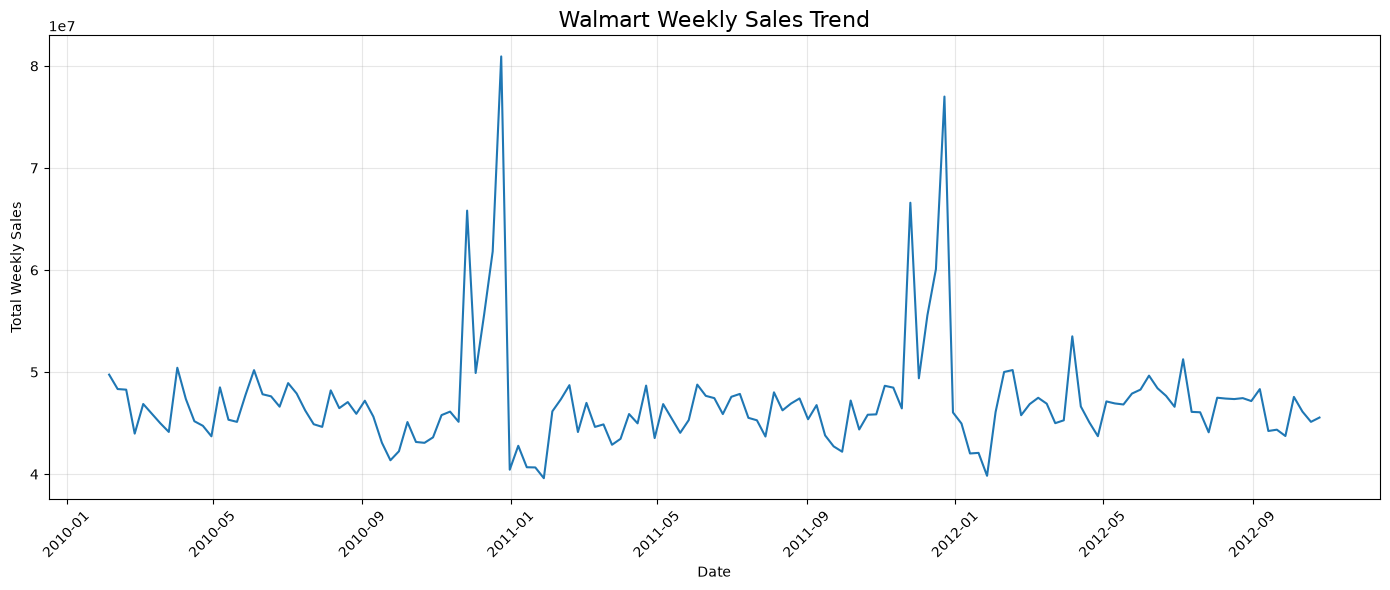

In [29]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=weekly_sales,
    x="Date",
    y="Weekly_Sales"
)

plt.title("Walmart Weekly Sales Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

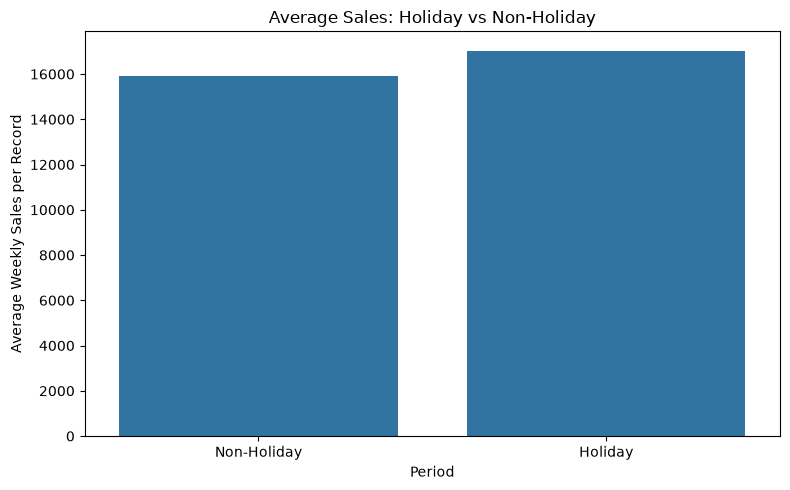

     IsHoliday  Weekly_Sales
0  Non-Holiday  15901.445069
1      Holiday  17035.823187


In [30]:
holiday_sales = (
    train.groupby("IsHoliday")["Weekly_Sales"]
    .mean()
    .reset_index()
)

holiday_sales["IsHoliday"] = holiday_sales["IsHoliday"].map({
    False: "Non-Holiday",
    True: "Holiday"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=holiday_sales,
    x="IsHoliday",
    y="Weekly_Sales"
)

plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("Period")
plt.ylabel("Average Weekly Sales per Record")
plt.tight_layout()
plt.show()

print(holiday_sales)

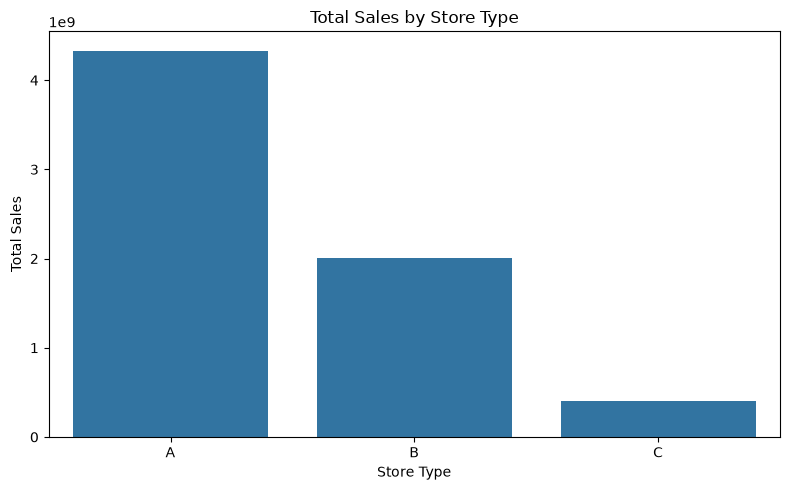

  Type  Weekly_Sales
0    A  4.331015e+09
1    B  2.000701e+09
2    C  4.055035e+08
  Type  Weekly_Sales
0    A  4.331015e+09
1    B  2.000701e+09
2    C  4.055035e+08


In [32]:
# Merge sales data with store information
store_data = train.merge(
    stores,
    on="Store",
    how="left"
)

# Calculate sales by store type
store_type_sales = (
    store_data.groupby("Type")["Weekly_Sales"]
    .sum()
    .reset_index()
    .sort_values("Weekly_Sales", ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=store_type_sales,
    x="Type",
    y="Weekly_Sales"
)

plt.title("Total Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

print(store_type_sales)
print(store_type_sales)

In [33]:
# Calculate total sales for each store
individual_store_sales = (
    store_data.groupby(["Store", "Type"])["Weekly_Sales"]
    .sum()
    .reset_index()
)

# Calculate average store sales by type
avg_store_sales = (
    individual_store_sales.groupby("Type")["Weekly_Sales"]
    .mean()
    .reset_index()
    .sort_values("Weekly_Sales", ascending=False)
)

print(avg_store_sales)

  Type  Weekly_Sales
0    A  1.968643e+08
1    B  1.176883e+08
2    C  6.758392e+07


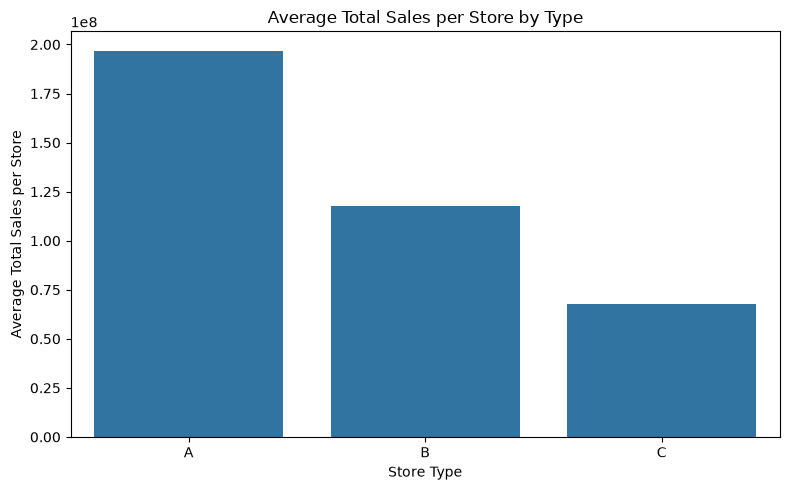

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=avg_store_sales,
    x="Type",
    y="Weekly_Sales"
)

plt.title("Average Total Sales per Store by Type")
plt.xlabel("Store Type")
plt.ylabel("Average Total Sales per Store")
plt.tight_layout()
plt.show()

In [35]:
# Calculate total sales by department
department_sales = (
    train.groupby("Dept")["Weekly_Sales"]
    .sum()
    .reset_index()
    .sort_values("Weekly_Sales", ascending=False)
)

# Display top 10 departments
top_10_depts = department_sales.head(10)

print(top_10_depts)

    Dept  Weekly_Sales
73    92  4.839433e+08
76    95  4.493202e+08
36    38  3.931181e+08
60    72  3.057252e+08
71    90  2.910685e+08
38    40  2.889360e+08
1      2  2.806112e+08
72    91  2.167817e+08
12    13  1.973216e+08
7      8  1.942808e+08


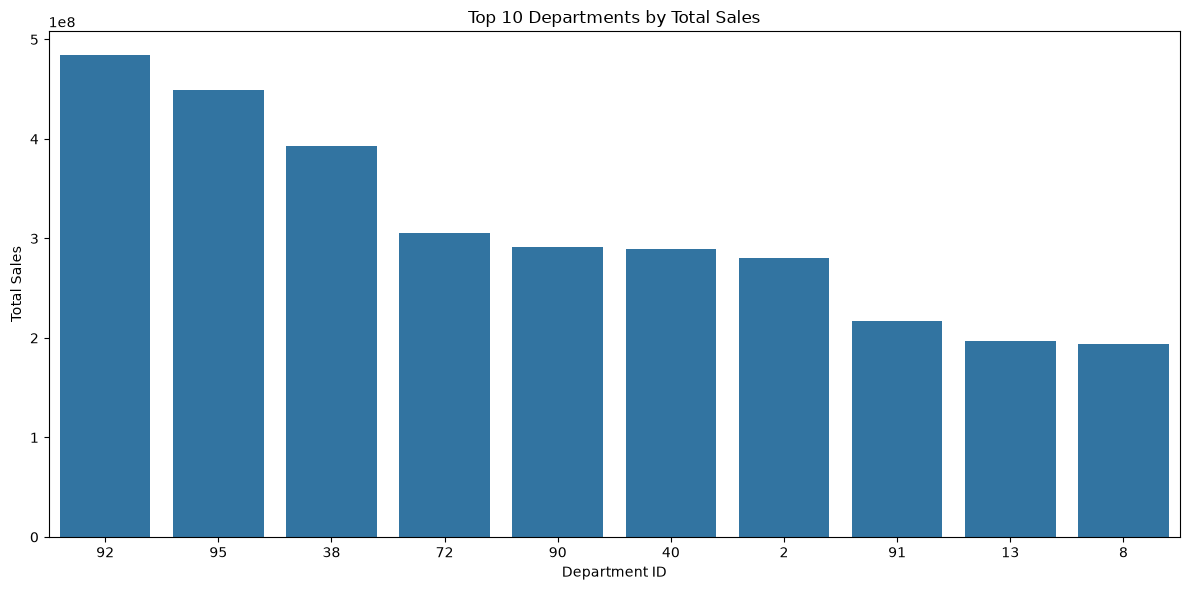

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_depts,
    x="Dept",
    y="Weekly_Sales",
    order=top_10_depts["Dept"]
)

plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Department ID")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [37]:
# Extract year and month
train["YearMonth"] = train["Date"].dt.to_period("M")

# Calculate monthly sales
monthly_sales = (
    train.groupby("YearMonth")["Weekly_Sales"]
    .sum()
    .reset_index()
)

# Convert YearMonth to string for plotting
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

print(monthly_sales.head(10))
print("\nTotal months:", len(monthly_sales))

  YearMonth  Weekly_Sales
0   2010-02  1.903330e+08
1   2010-03  1.819198e+08
2   2010-04  2.314124e+08
3   2010-05  1.867109e+08
4   2010-06  1.922462e+08
5   2010-07  2.325801e+08
6   2010-08  1.876401e+08
7   2010-09  1.772679e+08
8   2010-10  2.171618e+08
9   2010-11  2.028534e+08

Total months: 33


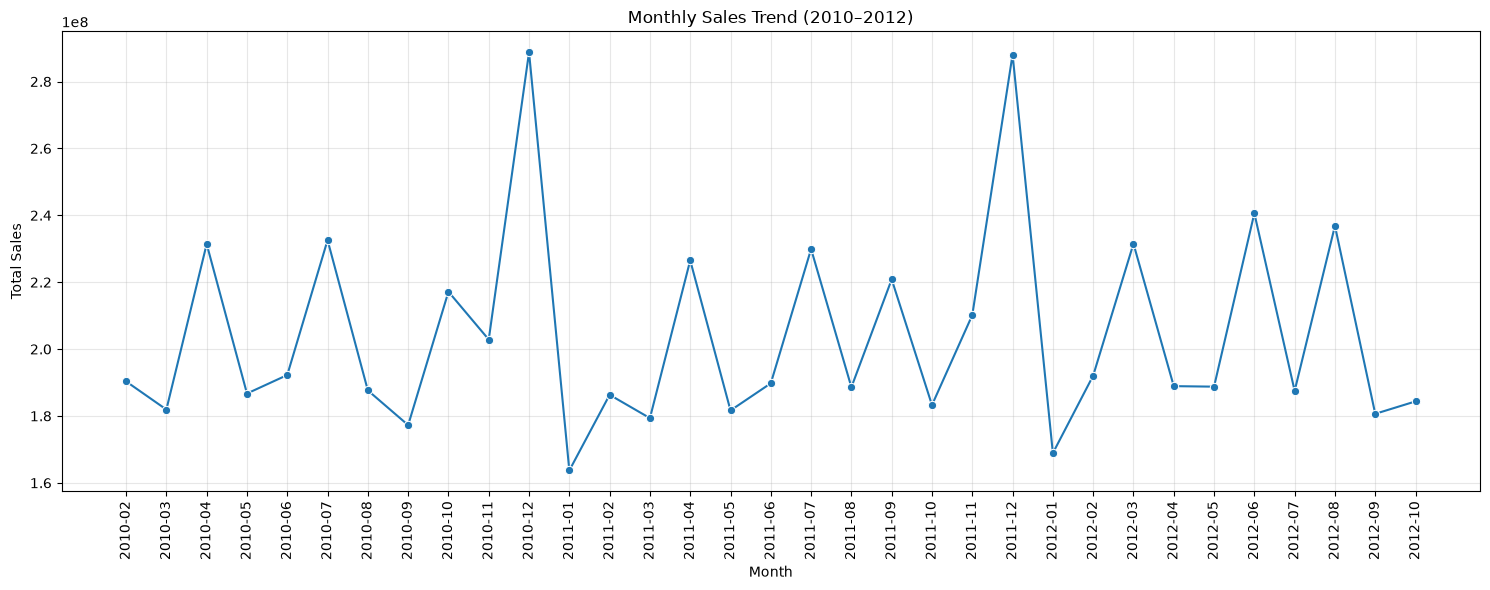

In [38]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Weekly_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2010–2012)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

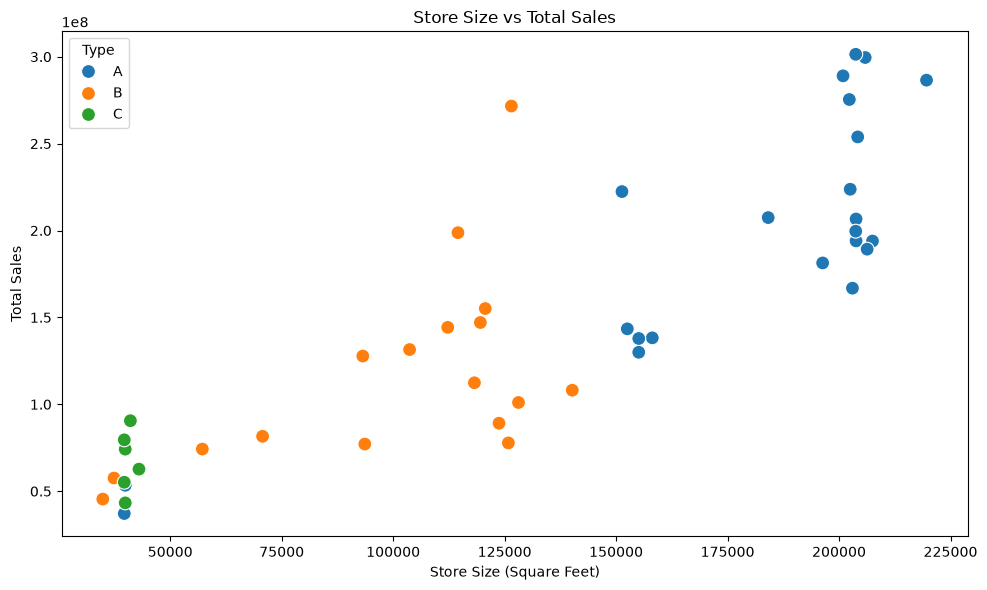

                  Size  Weekly_Sales
Size          1.000000      0.846161
Weekly_Sales  0.846161      1.000000


In [40]:
# Calculate total sales for each store
store_performance = (
    store_data.groupby(["Store", "Type", "Size"])["Weekly_Sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=store_performance,
    x="Size",
    y="Weekly_Sales",
    hue="Type",
    s=100
)

plt.title("Store Size vs Total Sales")
plt.xlabel("Store Size (Square Feet)")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

print(store_performance[["Size", "Weekly_Sales"]].corr())

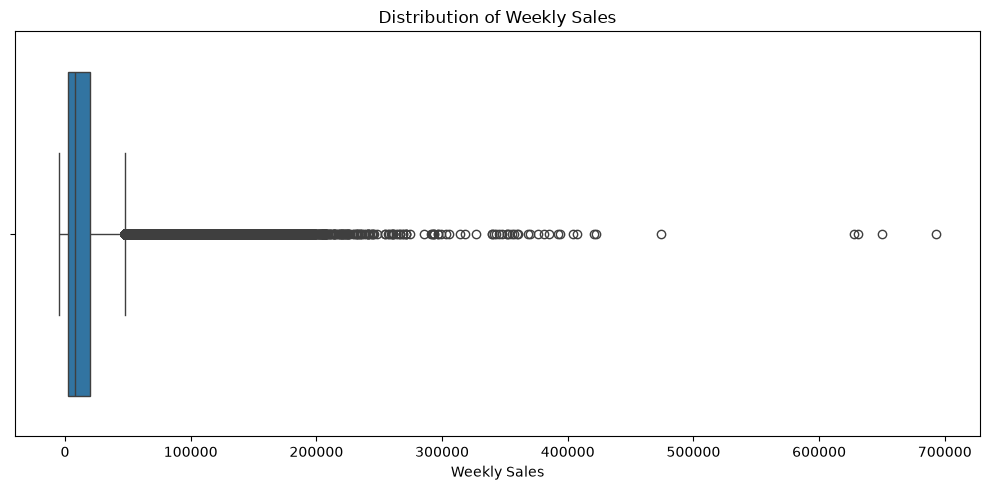

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64


In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=train["Weekly_Sales"])

plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.tight_layout()
plt.show()

print(train["Weekly_Sales"].describe())

In [42]:
# Merge sales with markdown information
markdown_data = train.merge(
    features[["Store", "Date", "MarkDown1", "MarkDown2",
              "MarkDown3", "MarkDown4", "MarkDown5"]],
    on=["Store", "Date"],
    how="left"
)

# Calculate total markdown
markdown_columns = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

markdown_data["Total_Markdown"] = (
    markdown_data[markdown_columns].fillna(0).sum(axis=1)
)

# Categorize records
markdown_data["Markdown_Status"] = (
    markdown_data["Total_Markdown"]
    .apply(lambda x: "With Markdown" if x > 0 else "Without Markdown")
)

# Compare average sales
markdown_comparison = (
    markdown_data.groupby("Markdown_Status")["Weekly_Sales"]
    .agg(["count", "mean", "sum"])
    .reset_index()
)

print(markdown_comparison)

ValueError: You are trying to merge on datetime64[us] and str columns for key 'Date'. If you wish to proceed you should use pd.concat

In [43]:
# Convert features Date into datetime format
features["Date"] = pd.to_datetime(features["Date"])

# Verify both data types
print("Train Date:", train["Date"].dtype)
print("Features Date:", features["Date"].dtype)

Train Date: datetime64[us]
Features Date: datetime64[us]


In [44]:
markdown_data = train.merge(
    features[["Store", "Date", "MarkDown1", "MarkDown2",
              "MarkDown3", "MarkDown4", "MarkDown5"]],
    on=["Store", "Date"],
    how="left"
)

print("Merged shape:", markdown_data.shape)

Merged shape: (421570, 11)


In [45]:
markdown_columns = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

# Calculate total markdown amount
markdown_data["Total_Markdown"] = (
    markdown_data[markdown_columns].fillna(0).sum(axis=1)
)

# Classify records
markdown_data["Markdown_Status"] = (
    markdown_data["Total_Markdown"]
    .apply(lambda x: "With Markdown" if x > 0 else "Without Markdown")
)

# Compare sales
markdown_comparison = (
    markdown_data.groupby("Markdown_Status")["Weekly_Sales"]
    .agg(["count", "mean", "sum"])
    .reset_index()
)

print(markdown_comparison)

    Markdown_Status   count          mean           sum
0     With Markdown  151432  16177.015244  2.449718e+09
1  Without Markdown  270138  15871.522017  4.287501e+09


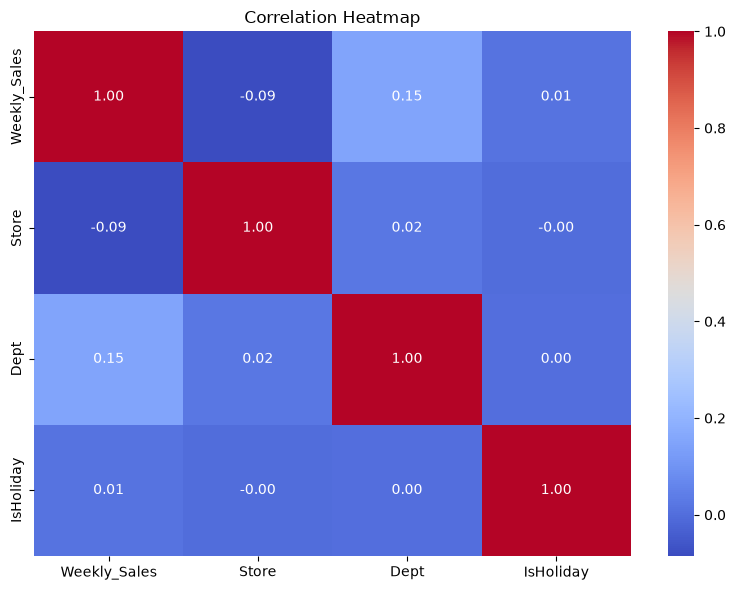

              Weekly_Sales     Store      Dept  IsHoliday
Weekly_Sales      1.000000 -0.085195  0.148032   0.012774
Store            -0.085195  1.000000  0.024004  -0.000548
Dept              0.148032  0.024004  1.000000   0.000916
IsHoliday         0.012774 -0.000548  0.000916   1.000000


In [46]:
# Select numerical columns
corr_data = train[
    ["Weekly_Sales", "Store", "Dept", "IsHoliday"]
].copy()

corr_data["IsHoliday"] = corr_data["IsHoliday"].astype(int)

# Calculate correlation
correlation = corr_data.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print(correlation)